# Refugee matching under endogenous shifts: simulation experiments

This notebook runs the feedback loop for different community effects (δ), different forms of the ground-truth model and two matching models (GBM, logistic regression).

**Structure**
1. Setup and synthetic population (Steps 1–2 of the generator)
2. Ground-truth outcome model: documentation and code
3. Sanity checks
4. Matching models and the simulation loop
5. Experiment grid (results are saved to `simulation_grid.csv` after every run)
6. Results

**Running it.** The full grid takes about 40 minutes on one CPU. Results are saved after every run, and finished runs are skipped when the grid is started again, so a session that stops can simply be resumed. With `RUN_GRID = False` the notebook only loads the saved results and draws the figures.

## 1. Setup and synthetic population

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit, logit
from scipy.stats import norm, truncnorm
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

In [2]:
# Marginal distributions (Strasser Ceballos & Kern 2025, Table 5)
P_MALE = 0.602
P_VOCATIONAL_TRAINING = 0.248
P_FREE_CASE = 0.539

AGE = {"mean": 32.0, "sd": 10.0, "low": 18, "high": 65}
SCHOOL_YEARS = {"mean": 9.9, "sd": 3.0, "low": 0, "high": 18}

COUNTRY_OF_ORIGIN = {
    "Syria": 52.8, "Iraq": 13.3, "Afghanistan": 12.5, "Eritrea": 4.3, "Iran": 2.3,
    "Pakistan": 1.7, "Russian Fed.": 1.5, "Somalia": 1.2, "Other": 10.4,
}
EDUCATION_LEVEL = {"low": 33.9, "medium": 26.8, "high": 39.3}
GERMAN_SPEAKING = {"none": 93.9, "poorly": 2.9, "fairly": 1.4, "good": 1.8}
RELIGION = {
    "Shiite": 60.6, "Sunnite": 7.6, "Other Islamic": 6.7, "Other Christian": 6.7,
    "No religion": 5.8, "Other": 6.2, "Protestant": 2.7, "Catholic": 2.5,
    "Christian Orthodox": 1.0,
}

# Königsteiner Schlüssel, current EASY quotas (BAMF, "Erstverteilung")
STATE_QUOTA = {
    "NW": 20.96090, "BY": 15.68563, "BW": 13.12509, "NI": 9.40263,
    "HE": 7.40812, "BE": 5.20075, "SN": 4.94788, "RP": 4.80876,
    "SH": 3.39588, "BB": 3.01025, "ST": 2.69612, "HH": 2.63402,
    "TH": 2.61509, "MV": 1.96964, "SL": 1.18749, "HB": 0.95455,
}

# Foreigners by state and nationality (Destatis GENESIS 12521-0021, 31 Dec 2025).
# Order: Syria, Iraq, Afghanistan, Eritrea, Iran, Pakistan, Russian Fed., Somalia,
#        all foreigners, average count per nationality outside these eight ("Other").
DESTATIS_COUNTS = {
    "NW": [280650, 87800, 75265, 16330, 44310, 16185, 54065, 12350, 3265705, 14099],
    "BY": [88860, 31755, 61580, 12405, 16095, 13755, 43305, 11460, 2386525, 11269],
    "BW": [93815, 29210, 44075, 9465, 13985, 13215, 33215, 5635, 2192400, 10483],
    "NI": [97685, 44760, 32700, 4080, 13150, 6065, 21645, 4560, 1084595, 4804],
    "HE": [59430, 10745, 69515, 18975, 18155, 21240, 20940, 13885, 1360875, 6164],
    "BE": [41455, 9970, 25070, 1950, 13375, 8850, 35165, 1340, 994590, 4635],
    "SN": [36320, 6255, 15035, 2065, 4350, 4605, 14005, 1200, 371045, 1710],
    "RP": [48700, 3980, 21310, 4025, 6400, 7070, 10320, 7135, 626355, 2991],
    "SH": [36225, 12390, 23380, 3550, 6050, 1590, 8660, 1670, 352575, 1570],
    "BB": [19435, 1530, 13675, 1335, 3330, 2770, 11505, 1515, 213330, 977],
    "ST": [29165, 2335, 9240, 1925, 2885, 1460, 4770, 1325, 192155, 897],
    "HH": [16800, 4540, 33060, 3650, 12250, 2055, 10620, 2020, 387845, 1731],
    "TH": [22280, 4265, 11480, 1890, 2070, 1570, 5120, 950, 187990, 929],
    "MV": [12685, 1375, 6520, 885, 1820, 470, 4190, 855, 125710, 659],
    "SL": [34640, 1215, 2145, 1180, 800, 785, 2410, 100, 164395, 781],
    "HB": [18135, 1930, 5725, 1025, 2765, 930, 4290, 2045, 164135, 816],
}

In [3]:
# ---------------------------------------------------------------------------
# Individual effects beta (log-odds scale)
# ---------------------------------------------------------------------------
# Source: Brücker, Jaschke & Kosyakova (2025), IAB-Forum "10 Jahre Fluchtmigration 2015",
# average marginal effects (AME) on the probability of paid employment, IAB-BAMF-SOEP survey
# linked to BA social-security records. They are associations, not causal effects.
#   medium school education  +3 pp   (reference: primary or no school)
#   higher school education  +5 pp, university +6 pp  -> our "high" uses the midpoint, +5.5 pp
#   good / very good German  +7 pp   (reference: all lower levels)
#   age 31-50                 ~0 pp, age 51-64  -14.5 pp   (reference: 18-30)
# AMEs are converted with beta = AME / (p (1 - p)); p = 0.4 approximates the mean employment
# rate in that sample (our approximation, not reported in the source).
AME_TO_LOGIT = 1 / (0.4 * 0.6)

BETA = {
    "male": None,                               # calibrated to the women/men ratio (TARGETS)
    "age_51_plus": -0.145 * AME_TO_LOGIT,       # IAB-Forum 2025
    "education_medium": 0.030 * AME_TO_LOGIT,   # IAB-Forum 2025
    "education_high": 0.055 * AME_TO_LOGIT,     # IAB-Forum 2025
    "german_good": 0.070 * AME_TO_LOGIT,        # IAB-Forum 2025
    "vocational_training": 0.12,                # placeholder, no published estimate in this form
    "free_case": 0.0,                           # placeholder, no evidence
}
# School years carry no separate effect (linked to education through the copula).
# Religion is generated but is not part of the outcome equation.

SIGMA_U = 0.5   # sd of unobserved individual differences u_i (placeholder)

# Employment rate of nationals of the eight main asylum countries by state, January 2026
# (Bundesagentur für Arbeit). Only relative differences between states are used.
STATE_EMPLOYMENT_RATE_BA = {
    "NW": 49.2, "BY": 55.3, "BW": 52.7, "NI": 48.0, "HE": 48.4, "BE": 49.9, "SN": 46.4, "RP": 49.6,
    "SH": 48.5, "BB": 44.2, "ST": 44.1, "HH": 54.8, "TH": 50.1, "MV": 44.6, "SL": 45.1, "HB": 46.3,
}

TARGETS = {
    "employment_rate": 0.15,        # baseline of the Strasser Ceballos & Kern (2025) case study
    "women_to_men_ratio": 31 / 75,  # IAB: 31% of women vs 75% of men employed (2015 cohort, 2022)
    "state_relative_level": {s: r / max(STATE_EMPLOYMENT_RATE_BA.values())
                             for s, r in STATE_EMPLOYMENT_RATE_BA.items()},
}

EDUCATION_SCHOOL_CORRELATION = 0.6

RELIGION_BY_ORIGIN_SHAPE = {
    #               Shiite Sunnite OthIsl OthChr NoRel Other Prot  Cath  Orth
    "Syria":        [5,    70,     8,     5,     4,    5,    1,    1,    1],
    "Iraq":         [45,   25,     3,     8,     3,    13,   1,    1,    1],
    "Afghanistan":  [20,   65,     3,     2,     5,    3,    1,    0.5,  0.5],
    "Eritrea":      [1,    30,     2,     15,    2,    2,    5,    5,    38],
    "Iran":         [45,   5,      3,     15,    15,   10,   4,    1,    2],
    "Pakistan":     [20,   70,     5,     2,     1,    1,    0.5,  0.5,  0.5],
    "Russian Fed.": [1,    70,     3,     2,     5,    3,    1,    1,    14],
    "Somalia":      [1,    92,     3,     1,     1,    1,    0.5,  0.5,  0.5],
    "Other":        [8,    30,     8,     12,    12,   10,   6,    6,    8],
}

COLUMNS = [
    "refugee_id", "sex", "age", "country_of_origin", "education_level", "school_years",
    "vocational_training", "german_speaking", "free_case", "religion",
    "assigned_state", "true_employment_prob", "employed",
]
STATES = list(STATE_QUOTA)
ORIGINS = list(COUNTRY_OF_ORIGIN)
ORIGIN_IDX = {o: i for i, o in enumerate(ORIGINS)}

In [4]:
def normalise(weights):
    """Percentages (dict or list) -> probability vector that sums to 1."""
    values = np.asarray(list(weights.values()) if isinstance(weights, dict) else weights, float)
    return values / values.sum()


def inverse_transform_sample(rng, distribution, n):
    """Draw n categories from {level: weight} by inverse transform sampling."""
    return categories_from_uniform(rng.random(n), distribution)


def bernoulli(rng, p, n):
    return rng.random(n) < p


def truncated_normal_params(mean, sd, low, high):
    """Shape parameters of a truncated normal on [low, high] whose mean after truncation is `mean`."""
    loc = mean
    for _ in range(50):
        a, b = (low - loc) / sd, (high - loc) / sd
        loc += mean - truncnorm.mean(a, b, loc=loc, scale=sd)
    return (low - loc) / sd, (high - loc) / sd, loc, sd


def truncated_normal(rng, n, mean, sd, low, high):
    a, b, loc, scale = truncated_normal_params(mean, sd, low, high)
    return truncnorm.rvs(a, b, loc=loc, scale=scale, size=n, random_state=rng)


def truncated_normal_from_uniform(u, mean, sd, low, high):
    """Same distribution as truncated_normal, but driven by given uniform numbers u."""
    a, b, loc, scale = truncated_normal_params(mean, sd, low, high)
    return truncnorm.ppf(u, a, b, loc=loc, scale=scale)


def categories_from_uniform(u, distribution):
    """Inverse transform: map uniform numbers u to categories with the given weights."""
    levels = np.array(list(distribution))
    cdf = np.cumsum(normalise(distribution))
    cdf[-1] = 1.0
    return levels[np.searchsorted(cdf, u, side="right")]


def iterative_proportional_fitting(shape, row_targets, column_targets, iterations=500, tol=1e-12):
    """Rescale a positive matrix until its row and column sums match the targets."""
    table = np.asarray(shape, float).copy()
    for _ in range(iterations):
        table *= (row_targets / table.sum(axis=1))[:, None]
        table *= (column_targets / table.sum(axis=0))[None, :]
        if np.abs(table.sum(axis=1) - row_targets).max() < tol:
            break
    return table


def religion_given_origin():
    """P(religion | origin): rows sum to 1, implied marginals match Table 5."""
    shape = [RELIGION_BY_ORIGIN_SHAPE[o] for o in ORIGINS]
    joint = iterative_proportional_fitting(shape, normalise(COUNTRY_OF_ORIGIN), normalise(RELIGION))
    return joint / joint.sum(axis=1, keepdims=True)


def initial_community_matrix():
    """C_0 (16 x 9): share of each origin among all foreigners in each state."""
    labels = ORIGINS[:-1] + ["all_foreigners", "Other"]
    counts = pd.DataFrame(DESTATIS_COUNTS, index=labels).T
    return counts[ORIGINS].div(counts["all_foreigners"], axis=0).loc[STATES].to_numpy()

In [5]:
def sample_attributes(n, rng):
    people = pd.DataFrame({
        "sex": np.where(bernoulli(rng, P_MALE, n), "male", "female"),
        "age": truncated_normal(rng, n, **AGE).round(1),
        "country_of_origin": inverse_transform_sample(rng, COUNTRY_OF_ORIGIN, n),
        "vocational_training": bernoulli(rng, P_VOCATIONAL_TRAINING, n),
        "german_speaking": inverse_transform_sample(rng, GERMAN_SPEAKING, n),
        "free_case": bernoulli(rng, P_FREE_CASE, n),
    })

    # Education level and years of school: Gaussian copula
    rho = EDUCATION_SCHOOL_CORRELATION
    z = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], size=n)
    u = norm.cdf(z)
    people["education_level"] = categories_from_uniform(u[:, 0], EDUCATION_LEVEL)
    people["school_years"] = truncated_normal_from_uniform(u[:, 1], **SCHOOL_YEARS).round(1)

    # Religion drawn conditionally on country of origin
    conditional = religion_given_origin()
    religion = np.empty(n, dtype=object)
    for i, origin in enumerate(ORIGINS):
        members = (people["country_of_origin"] == origin).to_numpy()
        religion[members] = inverse_transform_sample(
            rng, dict(zip(RELIGION, conditional[i])), members.sum())
    people["religion"] = religion

    return people[["sex", "age", "country_of_origin", "education_level", "school_years",
                   "vocational_training", "german_speaking", "free_case", "religion"]]


def capacities(n):
    """c_k = floor(N * q_k); leftover seats go to the largest remainders so that sum(c_k) = N."""
    q = normalise(STATE_QUOTA)
    c = np.floor(n * q).astype(int)
    c[np.argsort(-(n * q - c))[: n - c.sum()]] += 1
    return c


def assign_states(n, rng, mode="random"):
    """Quasi-random allocation by quota ("random" or "exact")."""
    if mode == "random":
        return inverse_transform_sample(rng, dict(zip(range(len(STATES)), STATE_QUOTA.values())), n).astype(int)
    if mode == "exact":
        return rng.permutation(np.repeat(np.arange(len(STATES)), capacities(n)))
    raise ValueError("mode must be 'random' or 'exact'")

## 2. Ground-truth outcome model


The ground truth is the rule that decides each synthetic refugee's true chance of finding a job in each German state. The matching algorithm never sees it; we use it to generate outcomes and to measure what really happens.

### Equation

p_i = sigmoid( α + β·X_i + γ[state] + community(z_i, zr_i, female_i) + u_i )

| Term | Meaning |
|---|---|
| α | baseline level |
| β·X_i | individual characteristics |
| γ[state] | labour-market level of the assigned state |
| community(...) | effect of the co-national community in that state |
| u_i ~ N(0, 0.5) | unobserved individual differences |

### Individual effects β

| Variable | β (log-odds) | Source |
|---|---|---|
| male | calibrated (≈ 1.06) | set so that women are employed 0.41 times as often as men: IAB, 31% vs 75% (2015 cohort, 2022) |
| education medium | 0.125 | +3 pp; IAB-Forum (Brücker, Jaschke & Kosyakova 2025) |
| education high | 0.229 | +5 pp (higher school) and +6 pp (university), midpoint 5.5 pp; same source |
| German good / very good | 0.292 | +7 pp; same source |
| age 51+ | −0.604 | −14.5 pp vs. age 18–30; no difference for 31–50; same source |
| vocational training | 0.12 | placeholder, no published estimate in this form |
| free case | 0 | placeholder, no evidence |

The IAB-Forum article reports average marginal effects on the probability of paid employment, estimated on the IAB-BAMF-SOEP Survey of Refugees linked to Bundesagentur für Arbeit social-security records. They are converted to log-odds with β = AME / (p(1−p)) using p = 0.4, our approximation of the mean employment rate in that sample. The authors stress that these are associations, not causal effects.

Religion is generated as an attribute but is not part of the equation.

### State effects γ and baseline α

α and γ are calibrated, not chosen:
- α: overall employment rate of 15% (baseline of the Strasser Ceballos & Kern 2025 case study)
- γ: relative employment levels of the 16 states, from the Bundesagentur für Arbeit employment rate of nationals of the eight main asylum countries (January 2026)

Calibration is redone for every ground-truth model, so all models start from the same overall rate, gender ratio and state levels.

### Community effect

The community share C is the number of co-nationals divided by all foreigners in the state (Destatis 12521-0021, 31 Dec 2025), updated after every round with the new placements. It enters as a standardised value

z = (C − mean(C₀)) / sd(C₀),

with the mean and sd of the starting matrix kept fixed, so z grows when the algorithm places more co-nationals in a state. zr is the share of co-nationals who arrived in the previous round, in the same units.

| Form | Formula | Meaning | Motivation |
|---|---|---|---|
| linear | δ·z | constant effect per sd of community size | baseline specification |
| inverted U | δ·z − κ·z² | small communities help, large ones hurt | networks help, but large communities compete for the same jobs |
| saturating | δ·tanh(z) | the effect flattens for very large communities | diminishing returns of additional contacts |
| women stronger | (δ + δ_f·female)·z | the effect is larger for women | Martén, Hainmueller & Hangartner (2019): women benefit most from co-national networks |
| stock vs recent | δ·z + δ_r·zr | established community helps, newly arrived co-nationals compete | Beaman (2012): more recent arrivals from the same network lower employment, longer-established members raise it |

### How large is δ?

No German estimate exists, so we use a range:

- **Martén, Hainmueller & Hangartner (2019, PNAS)**, Switzerland, quasi-random assignment of asylum seekers: about 20% of refugees assigned to a canton with a large co-national share were employed after three years, against 14% with a small share. That is about 0.4 on the log-odds scale across the range, or roughly 0.15–0.2 per standard deviation.
- **Upper bound:** the largest individual effect in the model is good German (0.29). We assume one sd of community size does not matter more than that.

Grid used: δ ∈ {−0.3, −0.15, 0, +0.15, +0.3}. Negative values represent labour-market congestion.

### Caveats

- With the logistic link, δ = 0 is not a pure null world: matching can still change total employment slightly. All community effects should be read relative to the δ = 0 run.
- The β values are associations from a published model, not estimates on our sample. They will be replaced by the true values once available.
- The community forms and the δ range are modelling choices; the experiments show how sensitive the results are to them.

In [6]:
def outcome_features(people):
    return pd.DataFrame({
        "male": (people["sex"] == "male").astype(float),
        "age_51_plus": (people["age"] > 50).astype(float),
        "education_medium": (people["education_level"] == "medium").astype(float),
        "education_high": (people["education_level"] == "high").astype(float),
        "german_good": (people["german_speaking"] == "good").astype(float),
        "vocational_training": people["vocational_training"].astype(float),
        "free_case": people["free_case"].astype(float),
    })


# Community effect: how the size of the co-national community changes the log-odds.
#   z   standardised community share (stock), z = (C - mean(C0)) / sd(C0), fixed moments
#   zr  co-nationals who arrived in the PREVIOUS round, in the same sd units (0 at the start)
#   f   1 for women, 0 for men
COMMUNITY_FORMS = {
    # constant effect per sd of community size
    "linear":          lambda z, zr, f, p: p["delta"] * z,
    # small communities help, large ones hurt (peak at z = delta / (2 kappa))
    "inverted_u":      lambda z, zr, f, p: p["delta"] * z - p["kappa"] * z ** 2,
    # diminishing returns: the effect flattens for very large communities
    "saturating":      lambda z, zr, f, p: p["delta"] * np.tanh(z),
    # interaction: the effect is larger for women (Martén et al. 2019 find women benefit most)
    "women_stronger":  lambda z, zr, f, p: (p["delta"] + p["delta_female"] * f) * z,
    # established community helps, newly arrived co-nationals compete (Beaman 2012)
    "stock_vs_recent": lambda z, zr, f, p: p["delta"] * z + p["delta_recent"] * zr,
}
DEFAULT_COMMUNITY_PARAMS = {"delta": 0.0, "kappa": 0.0, "delta_female": 0.0, "delta_recent": 0.0}


class GroundTruth:
    """p_i = sigmoid(alpha + beta'X_i + gamma[T_i] + community(z_i, zr_i, female_i) + u_i)

    form    one of COMMUNITY_FORMS
    params  parameters of that form (see DEFAULT_COMMUNITY_PARAMS)
    alpha, beta["male"] and gamma are calibrated to TARGETS at the starting community C0.
    """

    def __init__(self, form="linear", beta=BETA, sigma_u=SIGMA_U, targets=TARGETS,
                 calibration_seed=12345, calibration_size=50_000, **params):
        self.form = form
        self.params = {**DEFAULT_COMMUNITY_PARAMS, **params}
        self.beta = dict(beta)
        self.sigma_u = sigma_u
        self.C0 = initial_community_matrix()
        self.c_mean, self.c_sd = self.C0.mean(), self.C0.std()   # fixed baseline moments
        self.alpha = 0.0
        self.gamma = np.zeros(len(STATES))
        self._calibrate(targets, np.random.default_rng(calibration_seed), calibration_size)

    def label(self):
        shown = {k: v for k, v in self.params.items() if v != 0}
        return f"{self.form} {shown}" if shown else f"{self.form} (no effect)"

    def _community(self, people, C, R):
        """n x 16 matrix of community terms."""
        origin = people["country_of_origin"].map(ORIGIN_IDX).to_numpy()
        z = (C[:, origin].T - self.c_mean) / self.c_sd
        zr = R[:, origin].T / self.c_sd
        female = (people["sex"] == "female").to_numpy(float)[:, None]
        return COMMUNITY_FORMS[self.form](z, zr, female, self.params)

    def _individual(self, people, u):
        X = outcome_features(people)
        return X.to_numpy() @ np.array([self.beta[c] for c in X.columns]) + u

    def probability_all_states(self, people, u=None, C=None, R=None):
        """n x 16 matrix: true employment probability of every person in every state."""
        u = np.zeros(len(people)) if u is None else u
        C = self.C0 if C is None else C
        R = np.zeros_like(self.C0) if R is None else R
        score = (self.alpha + self._individual(people, u)[:, None] + self.gamma[None, :]
                 + self._community(people, C, R))
        return expit(score)

    def probability(self, people, states, u=None, C=None, R=None):
        return self.probability_all_states(people, u, C, R)[np.arange(len(people)), states]

    def _calibrate(self, targets, rng, n):
        people = sample_attributes(n, rng)
        u = rng.normal(0, self.sigma_u, n)
        q = normalise(STATE_QUOTA)
        male = (people["sex"] == "male").to_numpy()
        X = outcome_features(people)
        other = [c for c in X.columns if c != "male"]
        base = (X[other].to_numpy() @ np.array([self.beta[c] for c in other]) + u)[:, None]
        base = base + self._community(people, self.C0, np.zeros_like(self.C0))
        relative = np.array([targets["state_relative_level"][s] for s in STATES])
        state_target = relative * targets["employment_rate"] / (q @ relative)

        def probs():
            return expit(self.alpha + base + self.beta["male"] * male[:, None] + self.gamma[None, :])

        def bisect(error, lo, hi, steps=50):
            for _ in range(steps):
                mid = (lo + hi) / 2
                lo, hi = (mid, hi) if error(mid) < 0 else (lo, mid)
            return (lo + hi) / 2

        def overall_error(a):
            self.alpha = a
            return (probs() @ q).mean() - targets["employment_rate"]

        def gender_error(b):
            self.beta["male"] = b
            e = probs() @ q
            return targets["women_to_men_ratio"] - e[~male].mean() / e[male].mean()

        self.beta["male"] = 0.0
        for _ in range(8):
            self.alpha = bisect(overall_error, -10, 10)
            self.beta["male"] = bisect(gender_error, 0, 5)
            self.gamma += logit(state_target) - logit(probs().mean(axis=0))
            self.gamma -= q @ self.gamma


def initial_stock():
    """Destatis counts: co-nationals N[state, origin] (16 x 9) and all foreigners T[state]."""
    labels = ORIGINS[:-1] + ["all_foreigners", "Other"]
    counts = pd.DataFrame(DESTATIS_COUNTS, index=labels).T.loc[STATES]
    return counts[ORIGINS].to_numpy(float), counts["all_foreigners"].to_numpy(float)


def update_community(N, T, states, origins, scale):
    """Add this round's placements (each simulated person = `scale` real people).

    Returns the new stock, the new share matrix C and the recent-arrival share matrix R.
    """
    placed = np.zeros_like(N)
    np.add.at(placed, (states, origins), 1)
    N = N + scale * placed
    T = T + scale * placed.sum(axis=1)
    return N, T, N / T[:, None], scale * placed / T[:, None]

## 3. Sanity checks

1. Every form keeps the calibration: overall employment 15% and women/men ratio 0.41 at the start.
2. Shape of each community effect over the observed range of z.
3. The community update reproduces C₀ from the Destatis stock.

In [7]:
FORMS_TO_SHOW = [
    ("linear", {"delta": 0.3}),
    ("linear", {"delta": -0.3}),
    ("inverted_u", {"delta": 0.3, "kappa": 0.15}),
    ("saturating", {"delta": 0.3}),
    ("women_stronger", {"delta": 0.15, "delta_female": 0.15}),
    ("stock_vs_recent", {"delta": 0.15, "delta_recent": -0.3}),
]
rng_check = np.random.default_rng(1)
check_people = sample_attributes(30_000, rng_check)
check_u = rng_check.normal(0, SIGMA_U, len(check_people))   # include unobserved differences
q = normalise(STATE_QUOTA)
male = (check_people["sex"] == "male").to_numpy()
rows = []
for form, params in FORMS_TO_SHOW:
    g = GroundTruth(form, **params)
    expected = g.probability_all_states(check_people, check_u) @ q
    rows.append({"model": g.label(), "employment rate": round(expected.mean(), 4),
                 "women/men": round(expected[~male].mean() / expected[male].mean(), 3)})
pd.DataFrame(rows)

,model,employment rate,women/men
0,linear {'delta': 0.3},0.1497,0.407
1,linear {'delta': -0.3},0.1497,0.411
2,"inverted_u {'delta': 0.3, 'kappa': 0.15}",0.1496,0.409
3,saturating {'delta': 0.3},0.1497,0.408
4,"women_stronger {'delta': 0.15, 'delta_female':...",0.1496,0.407
5,"stock_vs_recent {'delta': 0.15, 'delta_recent'...",0.1497,0.408


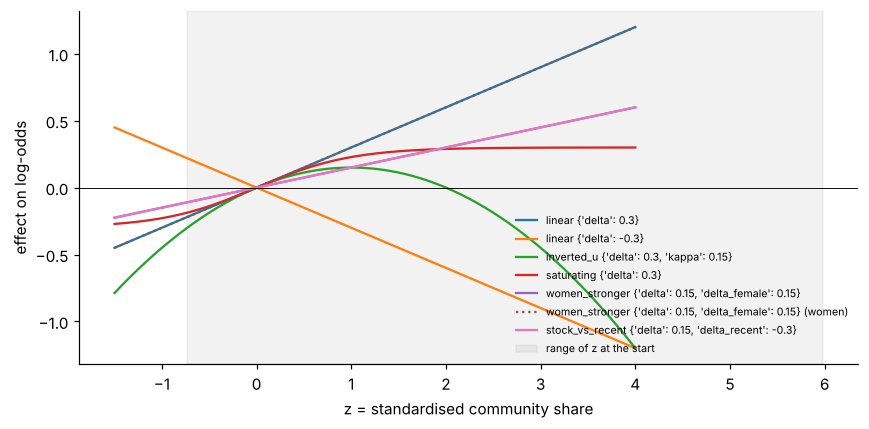

In [8]:
z = np.linspace(-1.5, 4, 200)
fig, ax = plt.subplots(figsize=(8, 4))
for form, params in FORMS_TO_SHOW:
    p = {**DEFAULT_COMMUNITY_PARAMS, **params}
    for female, ls in ((0, "-"), (1, ":")) if form == "women_stronger" else ((0, "-"),):
        y = COMMUNITY_FORMS[form](z, 0 * z, female, p)
        lbl = f"{form} {params}" + (" (women)" if female else "")
        ax.plot(z, y, ls, label=lbl)
C0 = initial_community_matrix()
z0 = (C0 - C0.mean()) / C0.std()
ax.axvspan(z0.min(), z0.max(), color="grey", alpha=0.1, label="range of z at the start")
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("z = standardised community share"); ax.set_ylabel("effect on log-odds")
ax.legend(fontsize=7, frameon=False); plt.tight_layout(); plt.show()

In [9]:
N0, T0 = initial_stock()
assert np.allclose(N0 / T0[:, None], initial_community_matrix())
print("stock reproduces C0: ok")

stock reproduces C0: ok


## 4. Matching models and simulation loop

**Matching models.** Both see only the observable attributes (not religion) and the state.
- **GBM:** one gradient-boosting model with the state as a categorical feature.
- **Logistic:** logistic regression with state and origin × state terms, in the spirit of Ahani et al. (2021).

**One round.** A new cohort arrives → true probabilities in every state under the current community → the model predicts → optimal assignment under the state quotas → outcomes drawn from the true probability of the assigned state → metrics → the community stock is updated with the placements → new data join the history.

**Policies.** `fixed`: the model is trained once on historical quota data. `every_round`: retrained every round on all data so far.

**Metrics (all from the true probabilities):**
| Metric | Meaning |
|---|---|
| `gain_pct` | true employment gain over quota assignment, % |
| `promised_gain_pct` | gain the model expects, % |
| `regret` | gap to the oracle that knows the true probabilities |
| `calib_gap` | predicted minus true employment at the chosen states |
| `rmse_all` | prediction error over all states |
| `auc` | discrimination of the model on realised outcomes |
| `origin_gap`, `sex_gap` | differences in expected employment between origins / sexes |
| `mean_z_placed` | average community size where people are placed (how far the world has shifted) |

In [10]:
from scipy.optimize import linear_sum_assignment
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

EDU_IDX = {"low": 0, "medium": 1, "high": 2}
GER_IDX = {"none": 0, "poorly": 1, "fairly": 2, "good": 3}
N_STATES, N_ORIGINS = len(STATES), len(ORIGINS)


def observed_features(people):
    """What the matching algorithm sees. Religion is deliberately left out."""
    return np.column_stack([
        (people["sex"] == "male").astype(float),
        people["age"],
        people["country_of_origin"].map(ORIGIN_IDX),
        people["education_level"].map(EDU_IDX),
        people["school_years"],
        people["vocational_training"].astype(float),
        people["german_speaking"].map(GER_IDX),
        people["free_case"].astype(float),
    ]).astype(float)


class GBMModel:
    """One gradient-boosting model with the state as a categorical feature."""
    name = "GBM"

    def __init__(self, seed=0):
        self.clf = HistGradientBoostingClassifier(
            max_iter=150, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=50,
            categorical_features=[2, 8], early_stopping=False, random_state=seed)

    def fit(self, people, states, y):
        self.clf.fit(np.column_stack([observed_features(people), states]), y)
        return self

    def predict_matrix(self, people):
        base = observed_features(people)
        n = len(base)
        stacked = np.vstack([np.column_stack([base, np.full(n, k)]) for k in range(N_STATES)])
        return self.clf.predict_proba(stacked)[:, 1].reshape(N_STATES, n).T


class LogitModel:
    """Logistic regression with state and origin x state terms (in the spirit of Ahani et al. 2021)."""
    name = "Logistic"

    def __init__(self, seed=0):
        self.clf = LogisticRegression(C=1.0, max_iter=1000)

    @staticmethod
    def _design(people, states):
        base = observed_features(people)
        n = len(base)
        numeric = np.column_stack([base[:, [0, 1, 4, 5, 7]], np.eye(3)[base[:, 3].astype(int)][:, 1:],
                                   np.eye(4)[base[:, 6].astype(int)][:, 1:]])
        numeric[:, 1] = (numeric[:, 1] - 32) / 10          # age, scaled
        numeric[:, 2] = (numeric[:, 2] - 10) / 3           # school years, scaled
        origin = np.eye(N_ORIGINS)[base[:, 2].astype(int)]
        state = np.eye(N_STATES)[states]
        inter = (origin[:, :, None] * state[:, None, :]).reshape(n, -1)
        return np.column_stack([numeric, origin[:, 1:], state[:, 1:], inter])

    def fit(self, people, states, y):
        self.clf.fit(self._design(people, states), y)
        return self

    def predict_matrix(self, people):
        n = len(people)
        return np.column_stack([self.clf.predict_proba(self._design(people, np.full(n, k)))[:, 1]
                                for k in range(N_STATES)])


POLICY_MODELS = {"GBM": GBMModel, "Logistic": LogitModel}


def assign_exact(scores, cap):
    """Maximum-weight assignment: state k receives exactly cap[k] people."""
    slots = np.repeat(np.arange(len(cap)), cap)
    rows, cols = linear_sum_assignment(-scores[:, slots])
    out = np.empty(scores.shape[0], dtype=int)
    out[rows] = slots[cols]
    return out


def run_simulation(truth, rounds=10, cohort_size=2000, n_hist=10000, retrain_every=None,
                   window=None, scale=50, seed=0, model="GBM"):
    """One run of the feedback loop.

    retrain_every  None = fixed model, 1 = retrain every round, k = every k rounds
    window         train only on the last `window` cohorts (None = all data)
    scale          real people represented by one simulated person (2,000 x 50 = 100,000 a year)
    The cohorts and noise depend only on `seed`, so all settings see the same people.
    """
    Model = POLICY_MODELS[model]
    rng_hist = np.random.default_rng(seed)
    rng_stream = np.random.default_rng(seed + 10_000)
    q = normalise(STATE_QUOTA)
    cap = capacities(cohort_size)
    idx = np.arange(cohort_size)

    N, T = initial_stock()
    C, R = N / T[:, None], np.zeros_like(N)

    # Round 0: historical data under random exact quota assignment at C0
    people0 = sample_attributes(n_hist, rng_hist)
    u0 = rng_hist.normal(0, truth.sigma_u, n_hist)
    s0 = assign_states(n_hist, rng_hist, mode="exact")
    y0 = bernoulli(rng_hist, truth.probability(people0, s0, u0, C, R), n_hist).astype(int)
    history = [(people0, s0, y0)]
    policy = Model(seed).fit(people0, s0, y0)

    logs = []
    for r in range(1, rounds + 1):
        if retrain_every and r > 1 and (r - 1) % retrain_every == 0:
            used = history if window is None else history[-window:]
            policy = Model(seed + r).fit(pd.concat([h[0] for h in used], ignore_index=True),
                                         np.concatenate([h[1] for h in used]),
                                         np.concatenate([h[2] for h in used]))

        people = sample_attributes(cohort_size, rng_stream)
        u = rng_stream.normal(0, truth.sigma_u, cohort_size)
        P = truth.probability_all_states(people, u, C, R)       # truth under the CURRENT world

        scores = policy.predict_matrix(people)
        pi = assign_exact(scores, cap)                            # algorithm
        pi_star = assign_exact(P, cap)                            # oracle (knows the truth)
        y = (rng_stream.random(cohort_size) < P[idx, pi]).astype(int)

        p_algo, p_star, p_rand = P[idx, pi], P[idx, pi_star], P @ q
        origin = people["country_of_origin"].to_numpy()
        origin_idx = people["country_of_origin"].map(ORIGIN_IDX).to_numpy()
        male = (people["sex"] == "male").to_numpy()
        by_origin = pd.Series(p_algo).groupby(origin).agg(["mean", "size"])
        by_origin = by_origin[by_origin["size"] >= 50]
        pred_chosen = scores[idx, pi]
        logs.append({
            "round": r,
            "welfare_algo": p_algo.mean(),
            "welfare_random": p_rand.mean(),
            "welfare_oracle": p_star.mean(),
            "gain_pct": 100 * (p_algo.mean() / p_rand.mean() - 1),
            "promised_gain_pct": 100 * (pred_chosen.mean() / p_rand.mean() - 1),
            "regret": p_star.mean() - p_algo.mean(),
            "calib_gap": pred_chosen.mean() - p_algo.mean(),
            "rmse_all": np.sqrt(np.mean((scores - P) ** 2)),
            "auc": roc_auc_score(y, pred_chosen),
            "origin_gap": by_origin["mean"].max() - by_origin["mean"].min(),
            "sex_gap": p_algo[male].mean() - p_algo[~male].mean(),
            "mean_z_placed": ((C[pi, origin_idx] - truth.c_mean) / truth.c_sd).mean(),
            "top_state_share_syria": np.bincount(pi[origin_idx == 0], minlength=N_STATES).max()
                                     / max((origin_idx == 0).sum(), 1),
            "realised": y.mean(),
        })

        N, T, C, R = update_community(N, T, pi, origin_idx, scale)   # feedback
        history.append((people, pi, y))

    return pd.DataFrame(logs)


def run_grid(configs, seeds=range(3), rounds=10, out="simulation_grid.csv", verbose=True):
    """Run every configuration for every seed and save after each run (safe if the session stops).

    configs: list of dicts with keys form, params, policy ("fixed"/"every_round"), model.
    Runs already present in `out` are skipped, so the grid can be resumed.
    """
    import os, time
    retrain = {"fixed": None, "every_round": 1, "every_3": 3}
    done = pd.read_csv(out) if os.path.exists(out) else pd.DataFrame()
    key = lambda c, s: f"{c['form']}|{sorted(c['params'].items())}|{c['policy']}|{c['model']}|{s}"
    finished = set(done["run_key"]) if len(done) else set()
    truths, start = {}, time.time()
    for cfg in configs:
        tkey = (cfg["form"], tuple(sorted(cfg["params"].items())))
        if tkey not in truths:
            truths[tkey] = GroundTruth(cfg["form"], **cfg["params"])
        for s in seeds:
            k = key(cfg, s)
            if k in finished:
                continue
            res = run_simulation(truths[tkey], rounds=rounds, retrain_every=retrain[cfg["policy"]],
                                 seed=s, model=cfg["model"])
            res["form"], res["policy"], res["model"], res["seed"] = cfg["form"], cfg["policy"], cfg["model"], s
            for p, v in cfg["params"].items():
                res[p] = v
            res["truth"] = truths[tkey].label()
            res["run_key"] = k
            done = pd.concat([done, res], ignore_index=True)
            done.to_csv(out, index=False)
            if verbose:
                print(f"{time.time() - start:6.0f}s  {k}", flush=True)
    return done

## 5. Experiment grid

| Experiment | Ground truth | Matching model | Policies |
|---|---|---|---|
| A | linear, δ ∈ {−0.3, −0.15, 0, 0.15, 0.3} | GBM | fixed, every round |
| B | inverted U, saturating (±), women stronger, stock vs recent | GBM | fixed, every round |
| C | linear, δ ∈ {−0.3, 0, 0.3} | Logistic | fixed, every round |

3 seeds, 8 rounds, 2,000 arrivals per round (each = 50 real people, about 100,000 a year).

In [11]:
RUN_GRID = False          # True: run (or resume) the grid; False: only load saved results
RESULTS = "simulation_grid.csv"

DELTAS = [-0.3, -0.15, 0.0, 0.15, 0.3]
POLICIES = ["fixed", "every_round"]
configs = [dict(form="linear", params={"delta": d}, policy=p, model="GBM") for d in DELTAS for p in POLICIES]
configs += [dict(form="linear", params={"delta": d}, policy=p, model="Logistic")
            for d in (-0.3, 0.0, 0.3) for p in POLICIES]
other_forms = [("inverted_u", {"delta": 0.3, "kappa": 0.15}),
               ("saturating", {"delta": 0.3}),
               ("saturating", {"delta": -0.3}),
               ("women_stronger", {"delta": 0.15, "delta_female": 0.15}),
               ("stock_vs_recent", {"delta": 0.15, "delta_recent": -0.3})]
configs += [dict(form=f, params=pr, policy=p, model="GBM") for f, pr in other_forms for p in POLICIES]

if RUN_GRID:
    grid = run_grid(configs, seeds=range(3), rounds=8, out=RESULTS)
grid = pd.read_csv(RESULTS)
print(f"{grid['run_key'].nunique()} runs, {len(grid)} rows")

78 runs, 624 rows


## 6. Results

### 6.1 Varying δ (linear community effect, GBM)

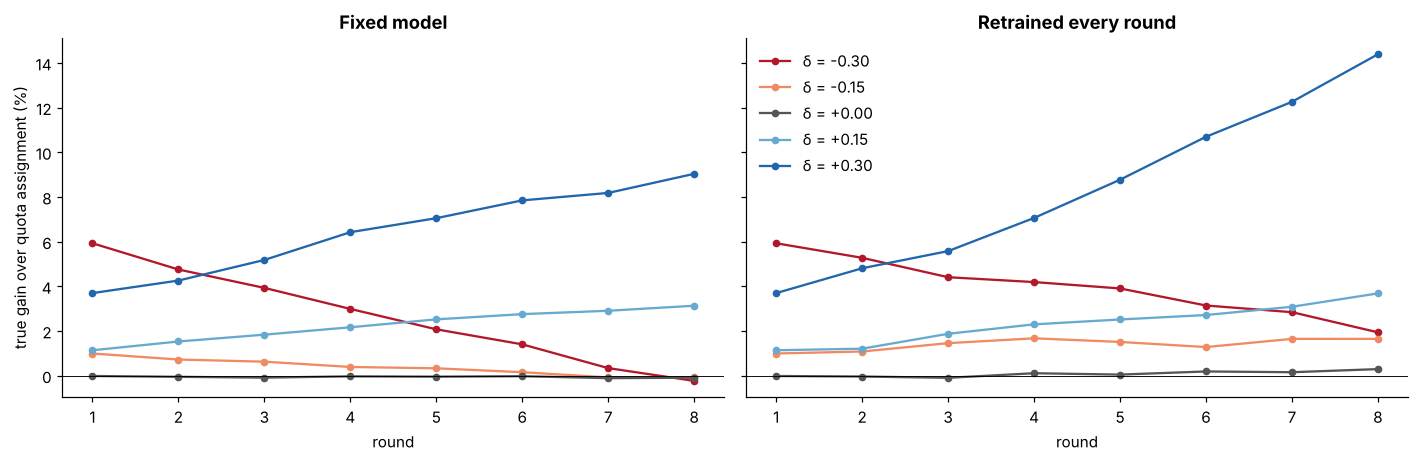

In [12]:
lin = grid[(grid["form"] == "linear") & (grid["model"] == "GBM")]
colors = {-0.3: "#B2182B", -0.15: "#EF8A62", 0.0: "#555555", 0.15: "#67A9CF", 0.3: "#2166AC"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, pol, title in zip(axes, POLICIES, ["Fixed model", "Retrained every round"]):
    m = lin[lin["policy"] == pol].groupby(["delta", "round"])["gain_pct"].mean().unstack(0)
    for d in DELTAS:
        ax.plot(m.index, m[d], "o-", ms=4, color=colors[d], label=f"δ = {d:+.2f}")
    ax.axhline(0, color="k", lw=0.6); ax.set_title(title, fontweight="bold"); ax.set_xlabel("round")
axes[0].set_ylabel("true gain over quota assignment (%)"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

In [13]:
table = (lin[lin["round"].isin([1, 8])]
         .groupby(["delta", "policy", "round"])[["gain_pct", "promised_gain_pct", "regret", "calib_gap", "auc", "mean_z_placed"]]
         .mean().round(3).unstack("round"))
table

gain_pct         promised_gain_pct         regret         \
round                    1       8                 1       8      1      8   
delta policy                                                                 
-0.30 every_round    5.925   1.938            34.684  22.451  0.013  0.012   
      fixed          5.925  -0.237            34.684  46.327  0.013  0.016   
-0.15 every_round    0.990   1.644            30.330  16.723  0.011  0.008   
      fixed          0.990  -0.081            30.330  36.626  0.011  0.011   
 0.00 every_round   -0.017   0.291            29.117  10.182  0.004  0.004   
      fixed         -0.017  -0.093            29.117  29.050  0.004  0.004   
 0.15 every_round    1.134   3.680            32.946   9.321  0.010  0.009   
      fixed          1.134   3.128            32.946  24.946  0.010  0.011   
 0.30 every_round    3.694  14.387            32.373   9.090  0.014  0.012   
      fixed          3.694   9.034            32.373  16.028  0.014  0.019   

                  calib_gap           auc        mean_z_placed         
round                     1      8      1      8             1      8  
delta policy                                                           
-0.30 every_round     0.043  0.028  0.636  0.655         0.499  1.064  
      fixed           0.043  0.064  0.636  0.630         0.499  1.145  
-0.15 every_round     0.044  0.022  0.609  0.627         0.648  1.088  
      fixed           0.044  0.053  0.609  0.621         0.648  1.155  
 0.00 every_round     0.044  0.015  0.609  0.621         0.718  1.210  
      fixed           0.044  0.044  0.609  0.614         0.718  1.240  
 0.15 every_round     0.048  0.009  0.616  0.643         0.821  1.434  
      fixed           0.048  0.035  0.616  0.627         0.821  1.436  
 0.30 every_round     0.043 -0.009  0.634  0.670         0.902  1.797  
      fixed           0.043  0.012  0.634  0.644         0.902  1.587

### 6.2 What the model promises vs. what really happens

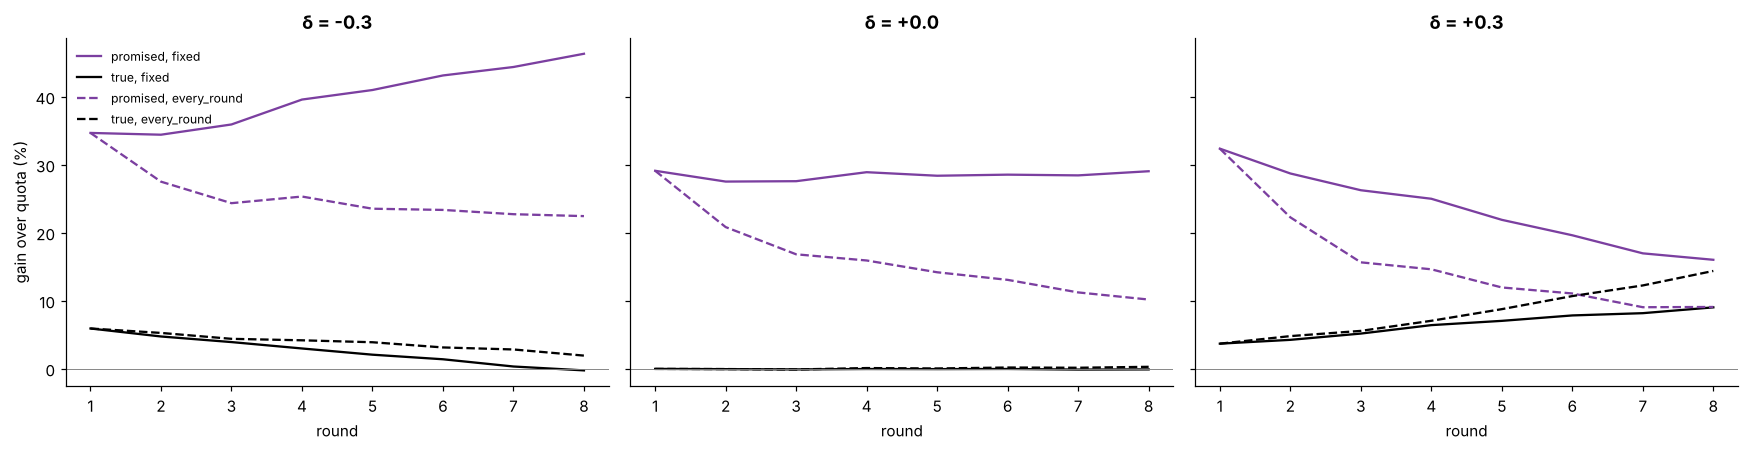

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, d in zip(axes, (-0.3, 0.0, 0.3)):
    for pol, ls in (("fixed", "-"), ("every_round", "--")):
        m = lin[(lin["delta"] == d) & (lin["policy"] == pol)].groupby("round")[["gain_pct", "promised_gain_pct"]].mean()
        ax.plot(m.index, m["promised_gain_pct"], ls, color="#7B3FA0", label=f"promised, {pol}")
        ax.plot(m.index, m["gain_pct"], ls, color="k", label=f"true, {pol}")
    ax.axhline(0, color="grey", lw=0.6); ax.set_title(f"δ = {d:+.1f}", fontweight="bold"); ax.set_xlabel("round")
axes[0].set_ylabel("gain over quota (%)"); axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

### 6.3 Different ground-truth models (GBM)

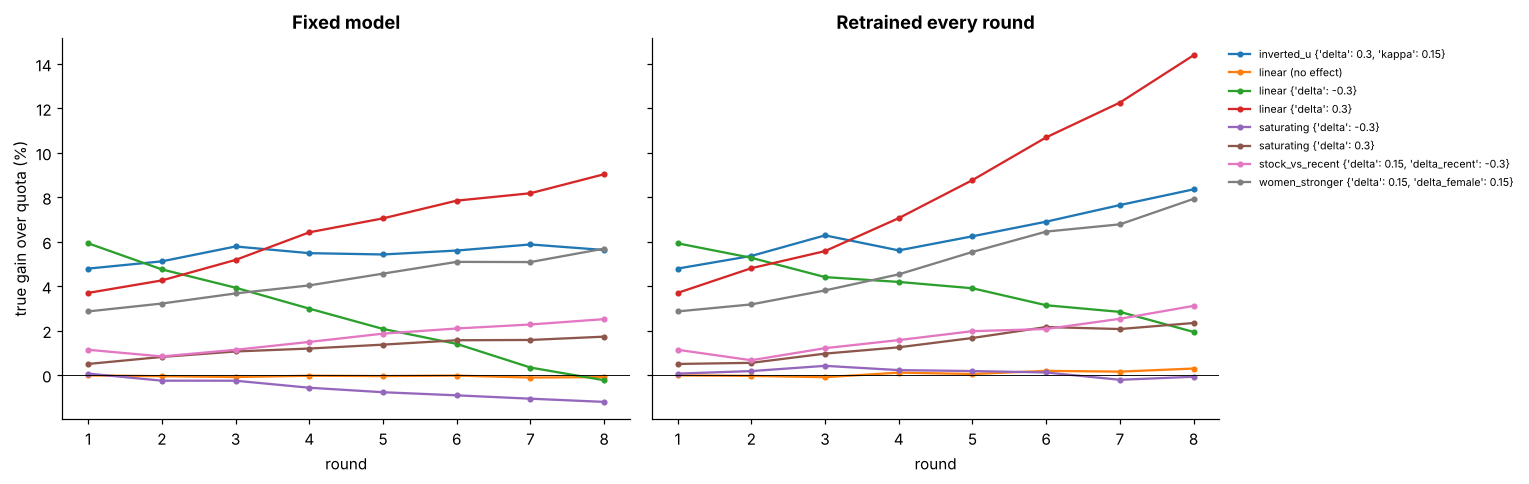

round                                                              1      8  \
truth                                              policy                     
inverted_u {'delta': 0.3, 'kappa': 0.15}           every_round  4.79   8.35   
                                                   fixed        4.79   5.62   
linear (no effect)                                 every_round -0.02   0.29   
                                                   fixed       -0.02  -0.09   
linear {'delta': -0.3}                             every_round  5.93   1.94   
                                                   fixed        5.93  -0.24   
linear {'delta': 0.3}                              every_round  3.69  14.39   
                                                   fixed        3.69   9.03   
saturating {'delta': -0.3}                         every_round  0.06  -0.08   
                                                   fixed        0.06  -1.21   
saturating {'delta': 0.3}                          every_round  0.50   2.34   
                                                   fixed        0.50   1.73   
stock_vs_recent {'delta': 0.15, 'delta_recent':... every_round  1.13   3.11   
                                                   fixed        1.13   2.51   
women_stronger {'delta': 0.15, 'delta_female': ... every_round  2.86   7.92   
                                                   fixed        2.86   5.69   

round                                                           change  
truth                                              policy               
inverted_u {'delta': 0.3, 'kappa': 0.15}           every_round    3.56  
                                                   fixed          0.83  
linear (no effect)                                 every_round    0.31  
                                                   fixed         -0.07  
linear {'delta': -0.3}                             every_round   -3.99  
                                                   fixed         -6.17  
linear {'delta': 0.3}                              every_round   10.70  
                                                   fixed          5.34  
saturating {'delta': -0.3}                         every_round   -0.14  
                                                   fixed         -1.27  
saturating {'delta': 0.3}                          every_round    1.84  
                                                   fixed          1.23  
stock_vs_recent {'delta': 0.15, 'delta_recent':... every_round    1.98  
                                                   fixed          1.38  
women_stronger {'delta': 0.15, 'delta_female': ... every_round    5.06  
                                                   fixed          2.83

In [15]:
forms = grid[(grid["model"] == "GBM") & ((grid["form"] != "linear") | grid["delta"].isin([-0.3, 0.0, 0.3]))]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, pol, title in zip(axes, POLICIES, ["Fixed model", "Retrained every round"]):
    m = forms[forms["policy"] == pol].groupby(["truth", "round"])["gain_pct"].mean().unstack(0)
    for col in m.columns:
        ax.plot(m.index, m[col], "o-", ms=3, label=col)
    ax.axhline(0, color="k", lw=0.6); ax.set_title(title, fontweight="bold"); ax.set_xlabel("round")
axes[0].set_ylabel("true gain over quota (%)"); axes[1].legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()
summary_forms = (forms[forms["round"].isin([1, 8])].groupby(["truth", "policy", "round"])["gain_pct"]
                 .mean().round(2).unstack("round"))
summary_forms["change"] = (summary_forms[8] - summary_forms[1]).round(2)
summary_forms

### 6.4 GBM vs. logistic regression

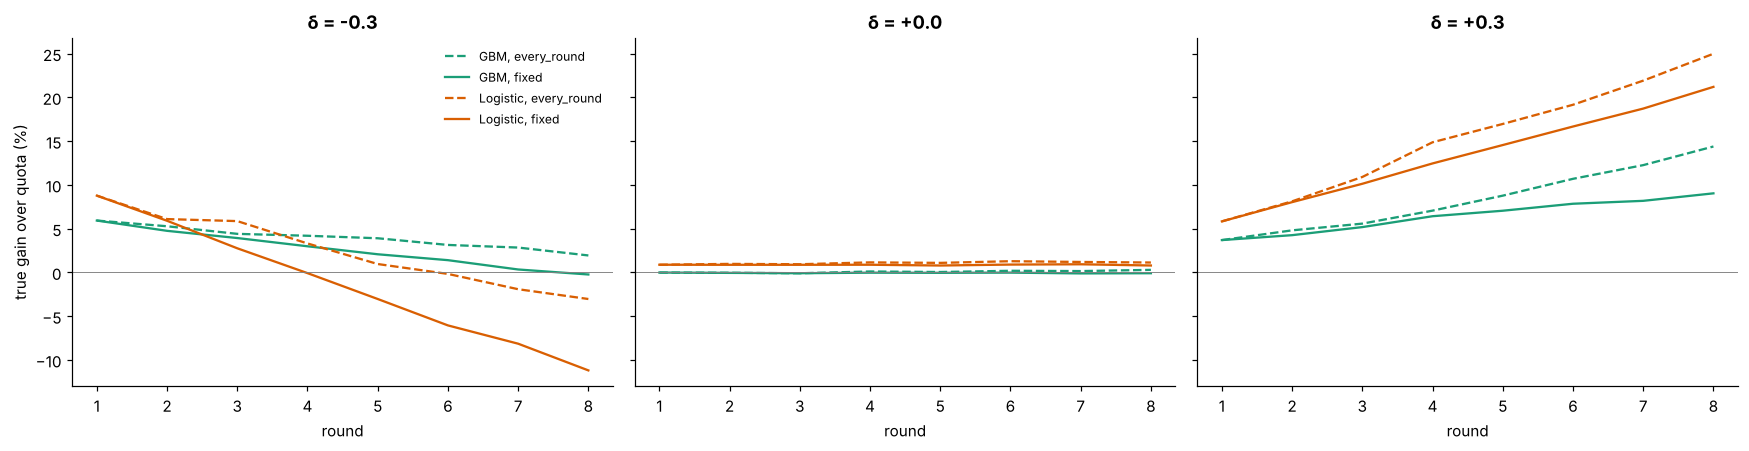

gain_pct  regret    auc
delta model    policy                              
-0.3  GBM      every_round     1.938   0.012  0.655
               fixed          -0.237   0.016  0.630
      Logistic every_round    -3.039   0.021  0.663
               fixed         -11.195   0.034  0.645
 0.0  GBM      every_round     0.291   0.004  0.621
               fixed          -0.093   0.004  0.614
      Logistic every_round     1.131   0.002  0.637
               fixed           0.790   0.003  0.632
 0.3  GBM      every_round    14.387   0.012  0.670
               fixed           9.034   0.019  0.644
      Logistic every_round    24.982   0.005  0.674
               fixed          21.199   0.009  0.641

In [16]:
comp = grid[(grid["form"] == "linear") & grid["delta"].isin([-0.3, 0.0, 0.3])]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, d in zip(axes, (-0.3, 0.0, 0.3)):
    for (mdl, pol), g in comp[comp["delta"] == d].groupby(["model", "policy"]):
        m = g.groupby("round")["gain_pct"].mean()
        ax.plot(m.index, m, "-" if pol == "fixed" else "--", color="#1B9E77" if mdl == "GBM" else "#D95F02",
                label=f"{mdl}, {pol}")
    ax.axhline(0, color="grey", lw=0.6); ax.set_title(f"δ = {d:+.1f}", fontweight="bold"); ax.set_xlabel("round")
axes[0].set_ylabel("true gain over quota (%)"); axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()
comp[comp["round"] == 8].groupby(["delta", "model", "policy"])[["gain_pct", "regret", "auc"]].mean().round(3)

### 6.5 Who is affected

In [17]:
last = lin[lin["round"] == 8].groupby(["delta", "policy"])[["origin_gap", "sex_gap", "mean_z_placed"]].mean().round(3)
last

origin_gap  sex_gap  mean_z_placed
delta policy                                         
-0.30 every_round       0.092    0.108          1.064
      fixed             0.098    0.104          1.145
-0.15 every_round       0.049    0.114          1.088
      fixed             0.053    0.107          1.155
 0.00 every_round       0.013    0.114          1.210
      fixed             0.011    0.111          1.240
 0.15 every_round       0.054    0.128          1.434
      fixed             0.051    0.123          1.436
 0.30 every_round       0.112    0.152          1.797
      fixed             0.107    0.139          1.587

## 7. Findings

All numbers are means over 3 seeds; "gain" is the true employment gain over quota assignment, measured with the ground-truth probabilities.

**1. Without a community effect there is nothing to gain, but the model promises a lot.** With δ = 0 the true gain stays below 0.3%, while the GBM model expects about +29% (winner's curse). This is the null baseline.

**2. Congestion: a model that is never retrained ends up worse than the quota.** With δ = −0.3 the gain falls from +5.9% in round 1 to −0.2% in round 8, while the model's promised gain rises from +35% to +46%. Retraining every round keeps the gain at about +2% and brings the promises closer to reality. With δ = −0.15 the pattern is the same but smaller.

**3. Network support: the gain grows over time.** With δ = +0.3 the gain rises from +3.7% to +9.0% (fixed) and +14.4% (retrained), because the algorithm builds up communities that help the next arrivals. With retraining the model's promises converge to the truth (calibration gap close to 0).

**4. The form of the community effect matters as much as its size.**
- Saturating effects (the effect flattens for large communities) give much smaller changes: +0.5% → +2.3% for support, and −1.2% by round 8 for congestion with a fixed model.
- Inverted U (small communities help, large ones hurt): the gain grows only slightly with a fixed model (+4.8% → +5.6%) but more with retraining (+8.4%).
- Stronger effect for women: the gain grows from +2.9% to +5.7% (fixed) and +7.9% (retrained).
- Established community helps but recent arrivals compete: the two forces partly cancel out, gains stay small (+1.1% → +2.5–3.1%).

**5. The matching model amplifies both directions.** The logistic model with origin × state terms learns the community pattern more directly. Under network support it reaches +21% to +25%, but under congestion with a fixed model it ends 11.2% below the quota, against −0.2% for GBM.

**6. Differences between groups grow with the community effect.** The gap in expected employment between countries of origin rises from about 1 percentage point at δ = 0 to about 10 points at δ = ±0.3. With network support the gap between men and women also widens (from 11 to 15 points at δ = +0.3).

**Caveats.** δ and the community forms are modelling choices within a literature-based range; the β values are published associations, not estimates on our sample. The conclusions are about directions and mechanisms, not exact sizes. They should be re-checked once the true β and δ values are available.